In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import false

In [2]:
df = pd.read_csv("CC GENERAL.csv")

In [3]:
df.head().T

,0,1,2,3,4
CUST_ID,C10001,C10002,C10003,C10004,C10005
BALANCE,40.900749,3202.467416,2495.148862,1666.670542,817.714335
BALANCE_FREQUENCY,0.818182,0.909091,1.0,0.636364,1.0
PURCHASES,95.4,0.0,773.17,1499.0,16.0
ONEOFF_PURCHASES,0.0,0.0,773.17,1499.0,16.0
INSTALLMENTS_PURCHASES,95.4,0.0,0.0,0.0,0.0
CASH_ADVANCE,0.0,6442.945483,0.0,205.788017,0.0
PURCHASES_FREQUENCY,0.166667,0.0,1.0,0.083333,0.083333
ONEOFF_PURCHASES_FREQUENCY,0.0,0.0,1.0,0.083333,0.083333
PURCHASES_INSTALLMENTS_FREQUENCY,0.083333,0.0,0.0,0.0,0.0


In [4]:
df.shape

(8950, 18)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

In [6]:
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

In [9]:
df["MINIMUM_PAYMENTS"].value_counts().sum()

np.int64(8637)

In [10]:
df["MINIMUM_PAYMENTS"] = df["MINIMUM_PAYMENTS"].fillna(df["MINIMUM_PAYMENTS"].median())
df["CREDIT_LIMIT"] = df["CREDIT_LIMIT"].fillna(df["CREDIT_LIMIT"].median())

In [11]:
df["MINIMUM_PAYMENTS"].isnull().sum()

np.int64(0)

In [12]:
NumericC = df.select_dtypes(include=["int64", "float64"])

In [61]:
(NumericC.columns).value_counts().sum()

np.int64(17)

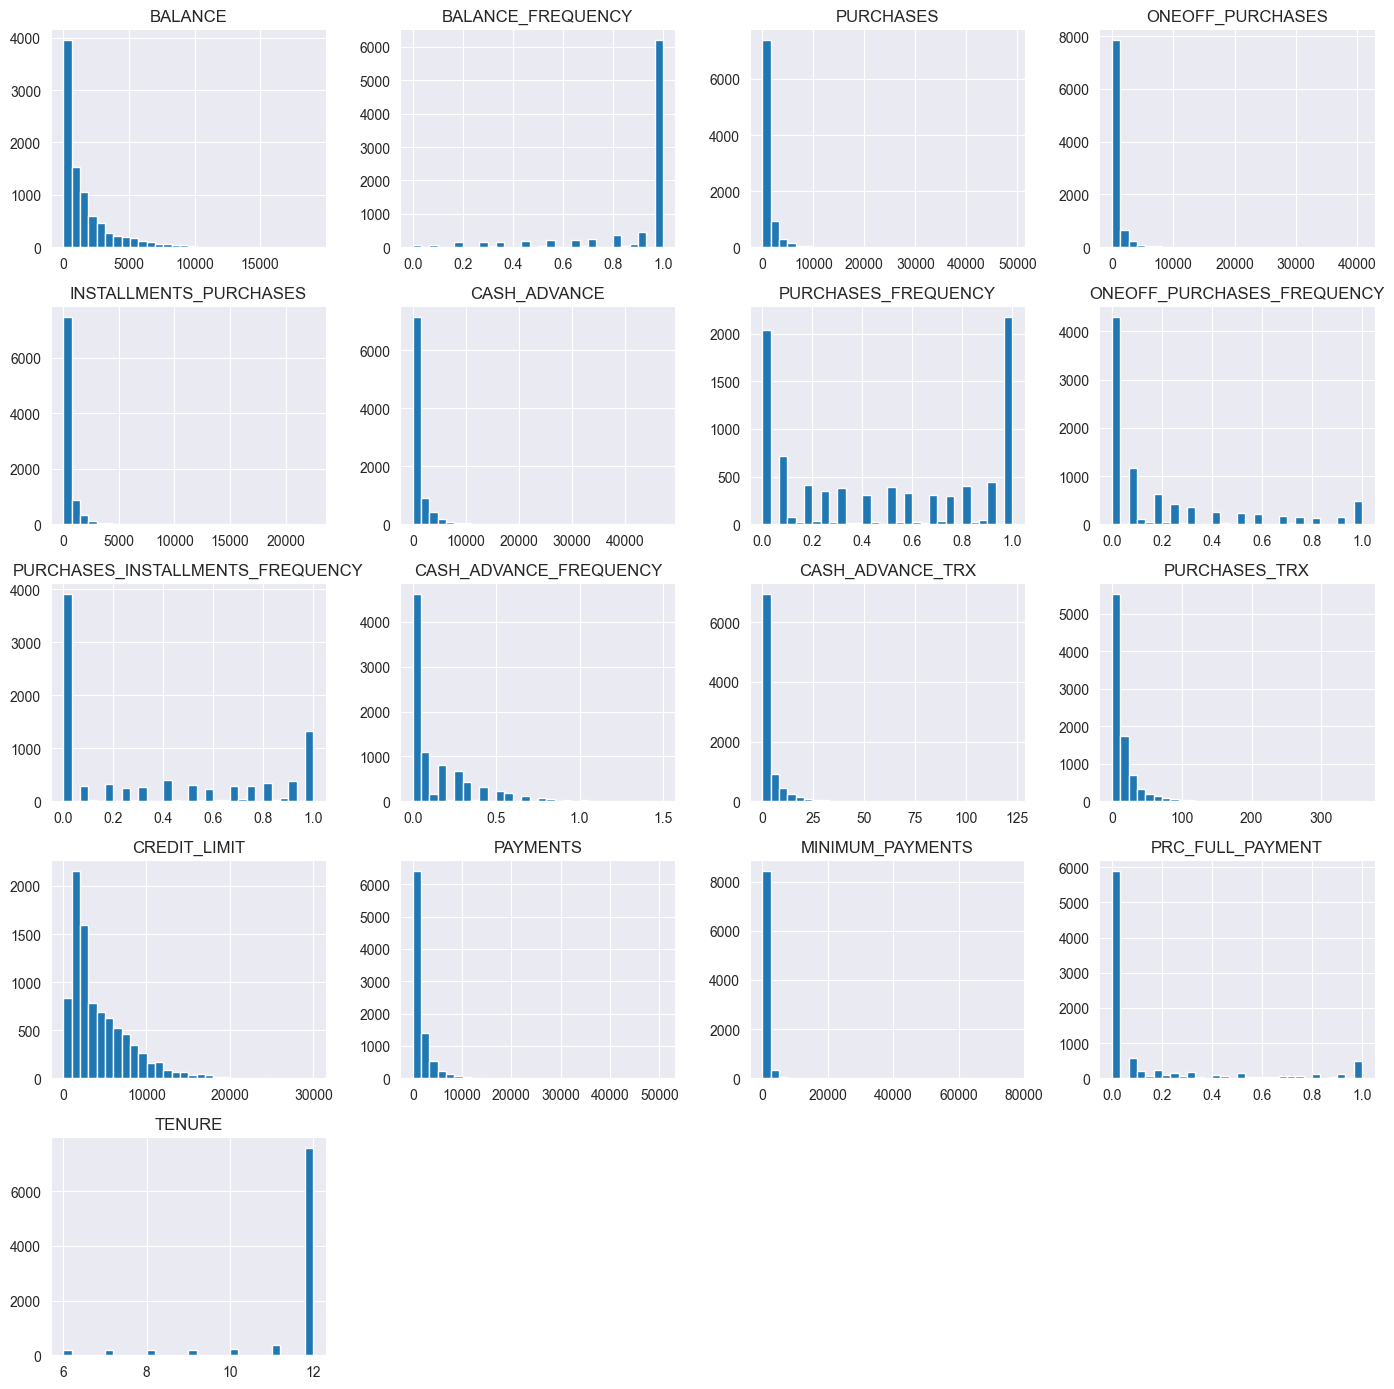

In [13]:
NumericC.hist(bins=30, figsize=(14, 14))
plt.tight_layout()
plt.show()

In [14]:
Corrr = NumericC.corr()

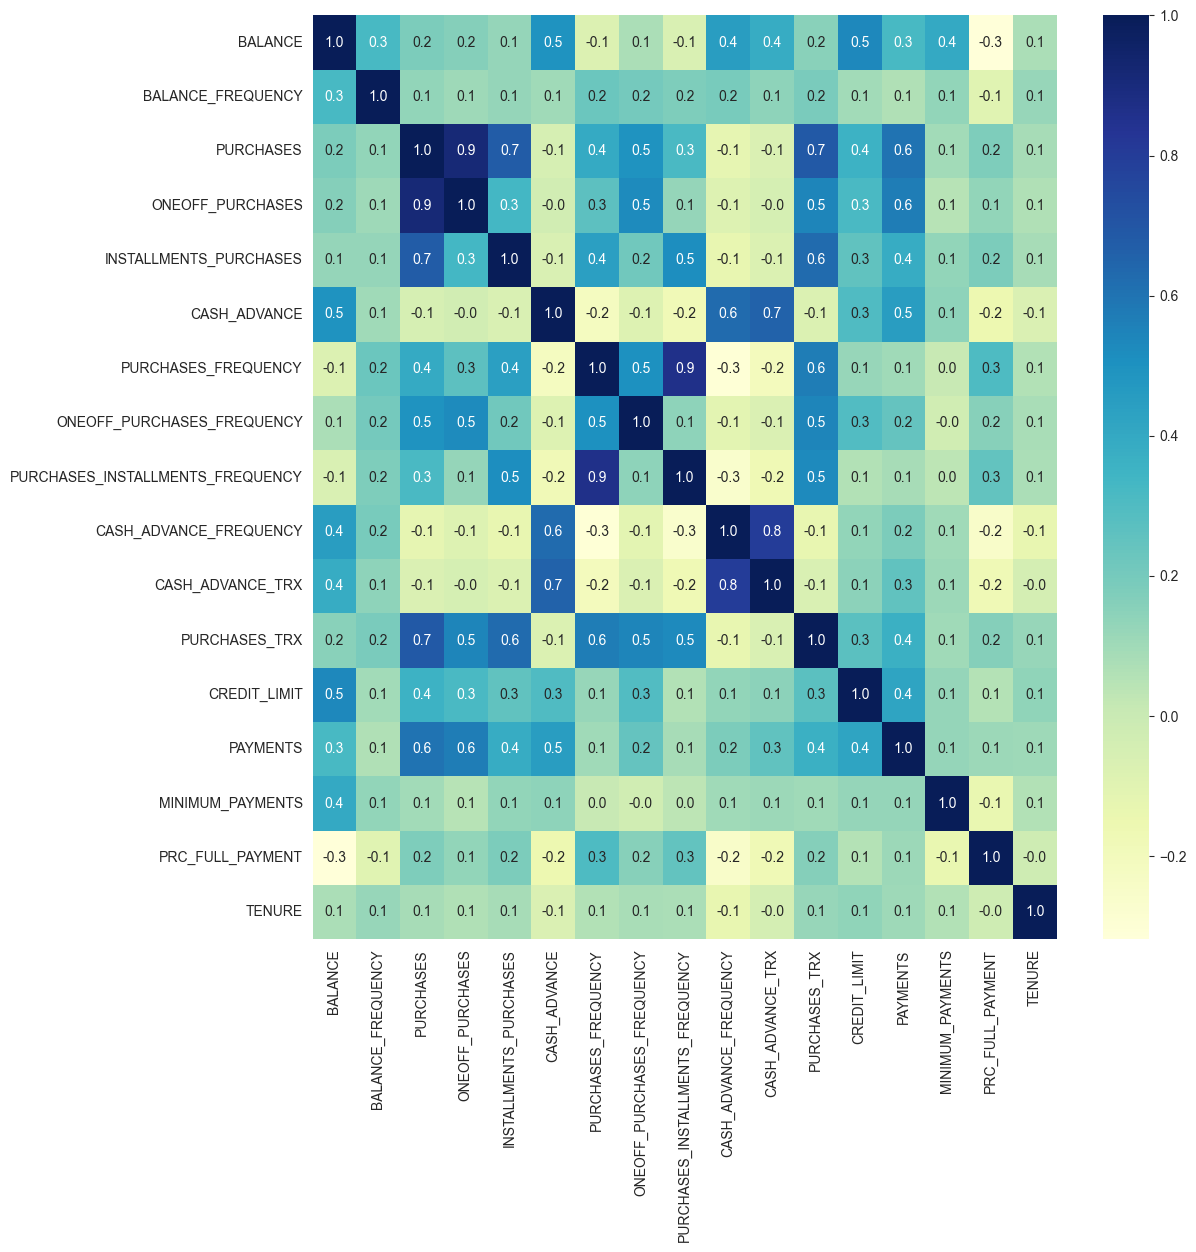

In [62]:
plt.figure(figsize=(12,12))
sns.heatmap(data=Corrr, annot=True, cmap="YlGnBu",fmt=".1f")
plt.show()

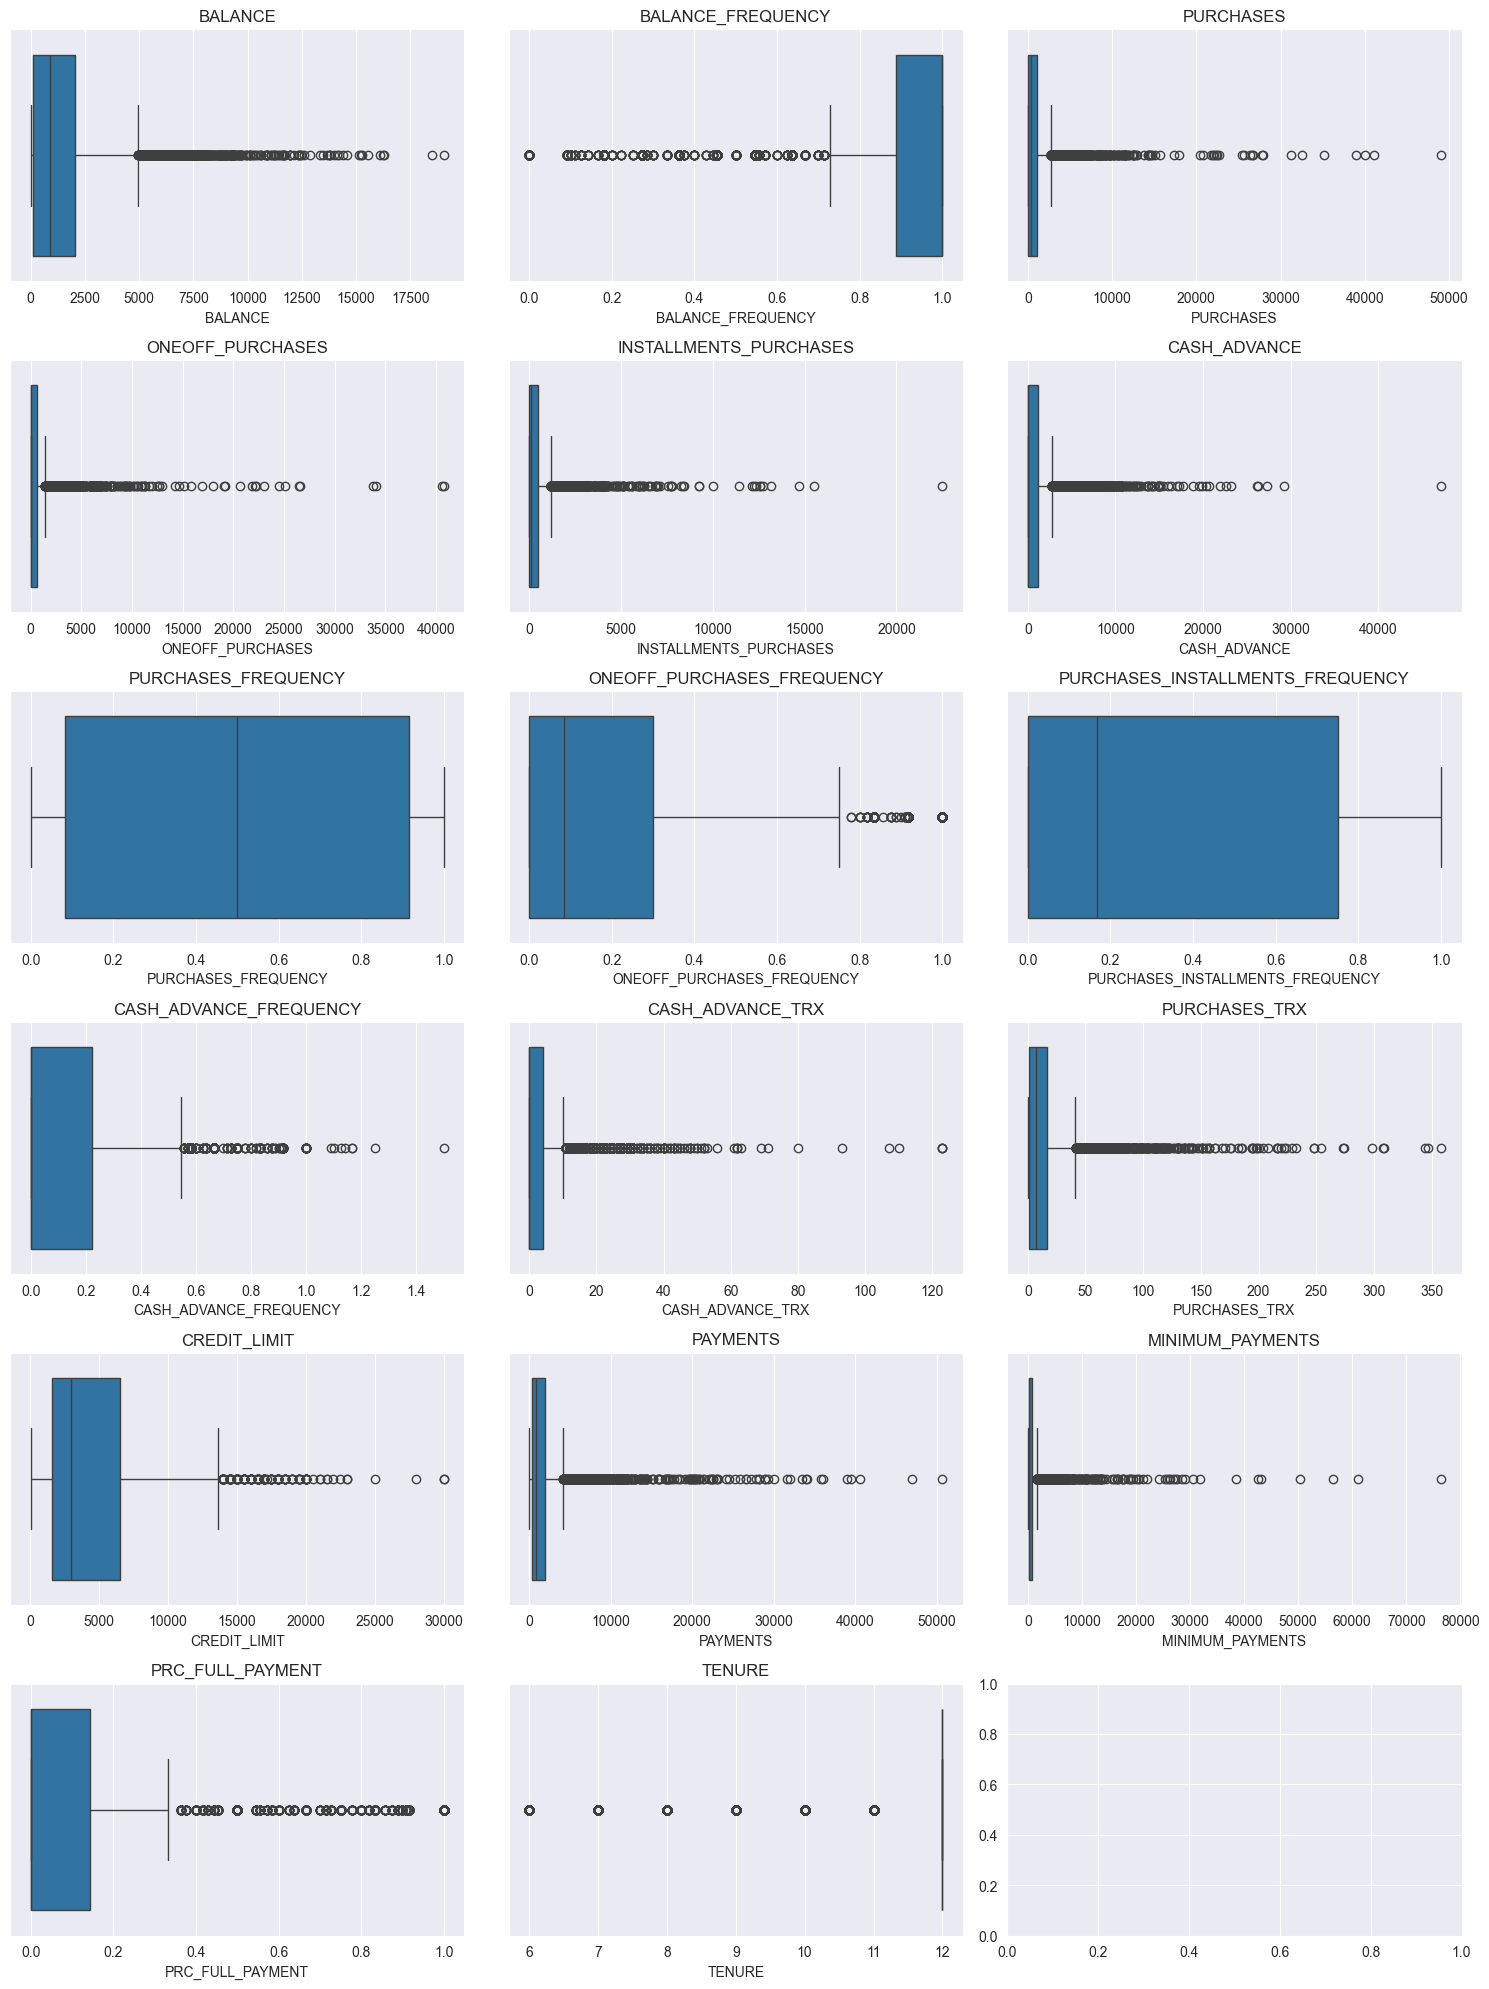

In [16]:
fig, axes = plt.subplots(6, 3, figsize=(15, 20))

for ax, col in zip(axes.flat, NumericC.columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

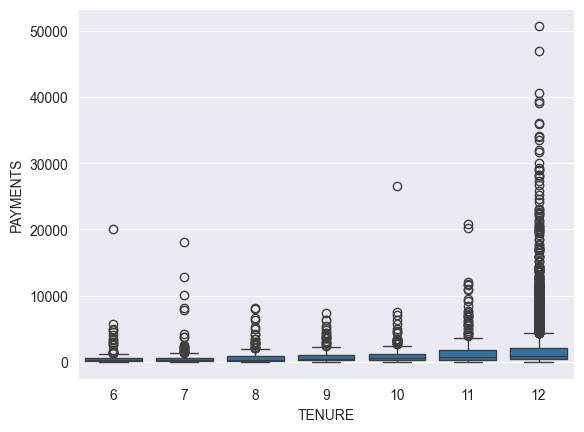

In [17]:
sns.boxplot(x=df["TENURE"], y=df["PAYMENTS"], data=df)
plt.show()

In [18]:
skew = NumericC.skew().sort_values(ascending=False)
print(skew)

MINIMUM_PAYMENTS                    13.852446
ONEOFF_PURCHASES                    10.045083
PURCHASES                            8.144269
INSTALLMENTS_PURCHASES               7.299120
PAYMENTS                             5.907620
CASH_ADVANCE_TRX                     5.721298
CASH_ADVANCE                         5.166609
PURCHASES_TRX                        4.630655
BALANCE                              2.393386
PRC_FULL_PAYMENT                     1.942820
CASH_ADVANCE_FREQUENCY               1.828686
ONEOFF_PURCHASES_FREQUENCY           1.535613
CREDIT_LIMIT                         1.522636
PURCHASES_INSTALLMENTS_FREQUENCY     0.509201
PURCHASES_FREQUENCY                  0.060164
BALANCE_FREQUENCY                   -2.023266
TENURE                              -2.943017
dtype: float64


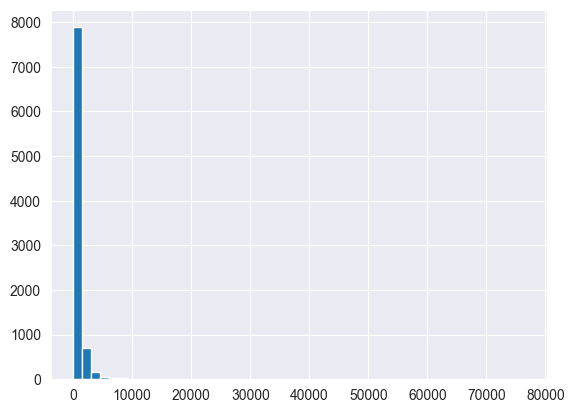

In [71]:
df["MINIMUM_PAYMENTS"].hist(bins=50)
plt.show()

In [19]:
X = df.drop("CUST_ID",axis=1)

In [20]:
from sklearn.preprocessing import PowerTransformer, StandardScaler

X_pt = pd.DataFrame(
    PowerTransformer(method="yeo-johnson").fit_transform(X),
    columns=X.columns
)
X_scaled = StandardScaler().fit_transform(X_pt)

In [77]:
pd.DataFrame({"before": X.skew(), "after": X_pt.skew()}).round(2).sort_values("before",ascending=False)

,before,after
MINIMUM_PAYMENTS,13.85,-0.03
ONEOFF_PURCHASES,10.05,0.12
PURCHASES,8.14,-0.18
INSTALLMENTS_PURCHASES,7.30,-0.01
PAYMENTS,5.91,0.12
CASH_ADVANCE_TRX,5.72,0.39
CASH_ADVANCE,5.17,0.19
PURCHASES_TRX,4.63,0.01
BALANCE,2.39,-0.12
PRC_FULL_PAYMENT,1.94,0.96


## PCA

In [22]:
from sklearn.decomposition import PCA

In [23]:
pca = PCA()
pca.fit(X_scaled)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [24]:
cum = pca.explained_variance_ratio_.cumsum() # kümülatif toplam
print(cum.round(3))

[0.358 0.583 0.683 0.76  0.828 0.875 0.915 0.945 0.966 0.975 0.982 0.988
 0.992 0.996 0.998 0.999 1.   ]


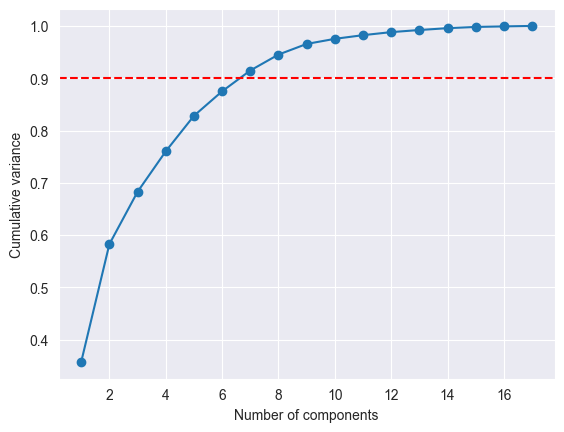

In [25]:
plt.plot(range(1, len(cum) + 1), cum, marker="*")
plt.axhline(0.90, color="r", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance")
plt.show()

In [26]:
pca = PCA(n_components=0.90)
X_pca = pca.fit_transform(X_scaled)

In [27]:
print(pca.n_components_)

7


In [28]:
X_pca.shape

(8950, 7)

In [29]:
pca.components_

array([[-0.13206833,  0.01116452,  0.35384874,  0.206607  ,  0.31717246,
        -0.29942079,  0.35542179,  0.21763182,  0.30944502, -0.29157739,
        -0.29438636,  0.36444299,  0.05061753,  0.0586489 , -0.10112323,
         0.17210926,  0.0670339 ],
       [ 0.4337605 ,  0.30332041,  0.17402786,  0.23295188,  0.07024872,
         0.24689358,  0.10857566,  0.23971418,  0.05609879,  0.25549076,
         0.2583398 ,  0.16796179,  0.25910417,  0.32125529,  0.37197989,
        -0.13765976,  0.09550388],
       [-0.05625927, -0.19200613,  0.09797771,  0.50492036, -0.38995586,
        -0.0997833 , -0.20271587,  0.47040157, -0.44706311, -0.10443953,
        -0.10866199, -0.06549256,  0.14698593,  0.04047506, -0.14174416,
        -0.02374405, -0.01620713],
       [-0.20267326, -0.35611377,  0.05637737,  0.00975144,  0.08731921,
         0.29259058,  0.05788961,  0.03102529,  0.06779485,  0.29849823,
         0.29232851,  0.04685575,  0.13673778,  0.31056045, -0.29051801,
         0.5125149 

## K-Means

In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [31]:
inertias = []
silhouette = []
ks = range(2, 11)

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    silhouette.append(silhouette_score(X_pca, labels))

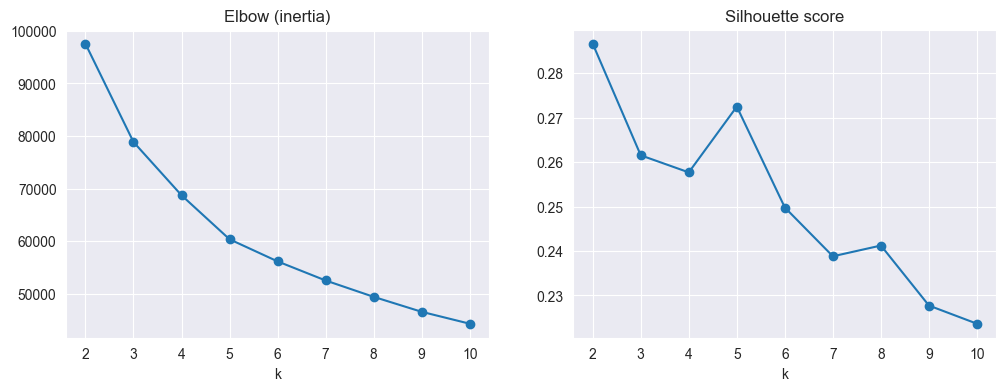

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(ks, inertias, marker="o")
axes[0].set_title("Elbow (inertia)")
axes[0].set_xlabel("k")

axes[1].plot(ks, silhouette, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")

plt.show()

In [33]:
from sklearn.metrics import davies_bouldin_score

k = 4
km = KMeans(n_clusters=k, random_state=42, n_init=10)
km_labels = km.fit_predict(X_pca)

df["kmeans"] = km_labels
print(df["kmeans"].value_counts().sort_index())
print("Silhouette:", silhouette_score(X_pca, km_labels))
print("Davies-Bouldin:", davies_bouldin_score(X_pca, km_labels))

kmeans
0    2666
1    1617
2    2583
3    2084
Name: count, dtype: int64
Silhouette: 0.2576796701393076
Davies-Bouldin: 1.4807888879245836


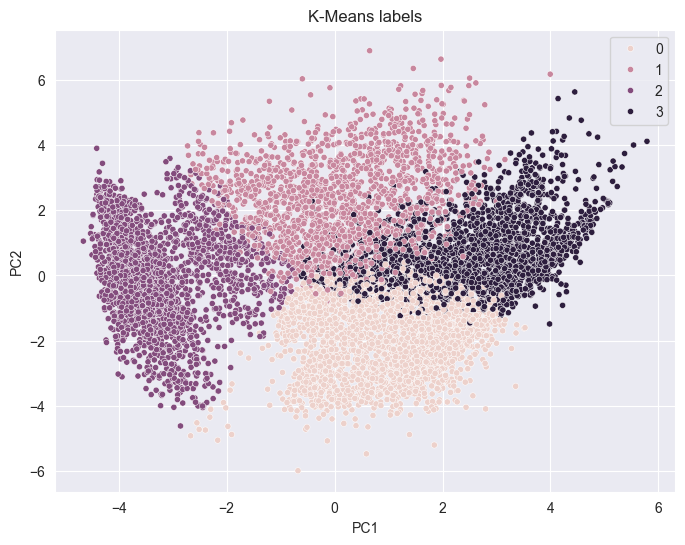

In [34]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=km_labels,s=20) #size: dot sizes.
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means labels")
plt.show()

In [35]:
Cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS","PURCHASES_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "PRC_FULL_PAYMENT"]

Profile = df.groupby("kmeans")[Cols].mean().round(1)
Profile["CustomerCount"] = df["kmeans"].value_counts().sort_index()
Profile

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,PRC_FULL_PAYMENT,CustomerCount
kmeans,,,,,,,,,
0,256.9,442.2,13.3,3162.8,638.4,0.6,0.0,0.3,2666
1,3017.2,1503.4,2301.2,5589.0,2799.4,0.7,0.3,0.0,1617
2,2126.2,38.5,1932.3,4000.6,1596.2,0.0,0.3,0.0,2583
3,1413.9,2528.5,6.3,5960.2,2476.0,0.8,0.0,0.2,2084


## Hierarchical Clustering

In [36]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

In [37]:
Z = linkage(X_pca, method="ward")

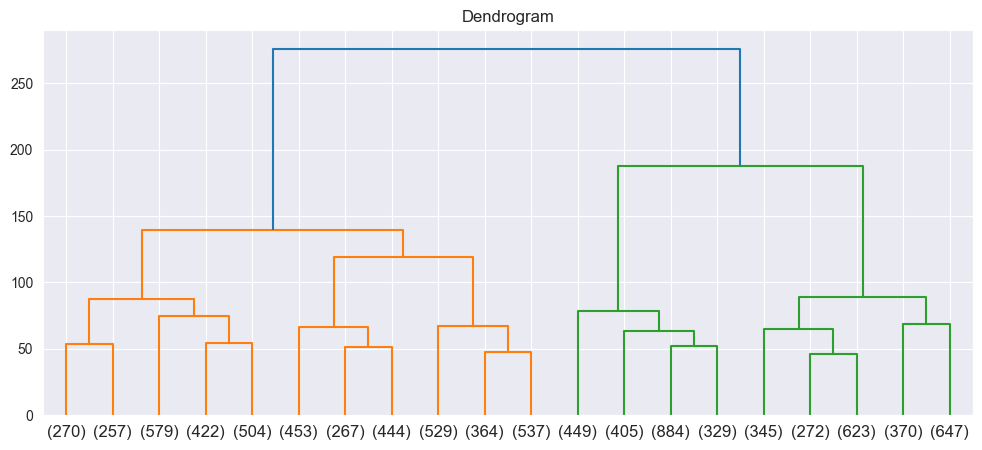

In [38]:
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20) # last 20 step
plt.title("Dendrogram")
plt.show()

In [39]:
agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
agg_labels = agg.fit_predict(X_pca)

In [40]:
df["hier"] = agg_labels
print(df["hier"].value_counts().sort_index())
print("Silhouette:", silhouette_score(X_pca, agg_labels))

hier
0    2594
1    2257
2    2067
3    2032
Name: count, dtype: int64
Silhouette: 0.2262620878341543


## DBSCAN

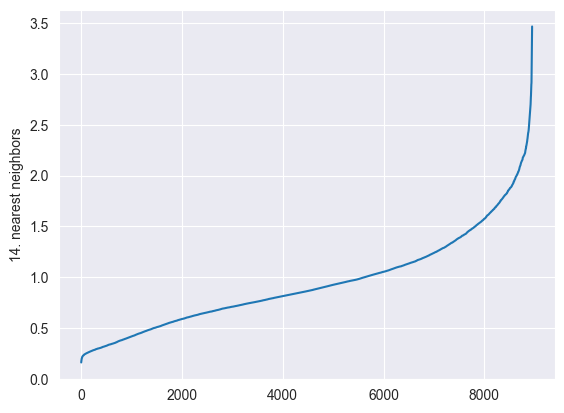

In [41]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

minSamples = 14 # 14 because. PCA is 7 and. The rule is == minSamples = PCA x 2
dist,indexx= NearestNeighbors(n_neighbors=minSamples).fit(X_pca).kneighbors(X_pca)

In [ ]:
plt.plot(np.sort(dist[:,-1]))
plt.ylabel(f"{minSamples}. nearest neighbors")
plt.show()

In [42]:
eps = 1.5    # change it according to the elbow in the k-distance plot

db = DBSCAN(eps=eps, min_samples=minSamples)
db_labels = db.fit_predict(X_pca)
df["dbscan"] = db_labels

In [43]:
print(df["dbscan"].value_counts().sort_index())    # -1 = noise

dbscan
-1     437
 0    4055
 1    3340
 2     439
 3     173
 4     295
 5      51
 6      49
 7     111
Name: count, dtype: int64


## HDBSCAN

In [44]:
from sklearn.cluster import HDBSCAN

hdb = HDBSCAN(min_cluster_size=50, copy=True)
hdb_labels = hdb.fit_predict(X_pca)
df["hdbscan"] = hdb_labels

In [45]:
print(df["hdbscan"].value_counts().sort_index())    # -1 = noise

hdbscan
-1    2852
 0     467
 1     318
 2    3742
 3      75
 4     193
 5     151
 6    1152
Name: count, dtype: int64


## Anomaly Detection (Isolation Forest)

In [46]:
from sklearn.ensemble import IsolationForest

In [47]:
X_raw = df.drop(columns=["CUST_ID", "kmeans", "hier", "dbscan", "hdbscan"])

iso = IsolationForest(contamination=0.05, random_state=42) # contamination = 5% of the data is expected to be anomaly
df["anomaly"] = iso.fit_predict(X_raw) == -1     # True = anomaly

In [48]:
print(df["anomaly"].sum(), "anomaly customer")
df.groupby("anomaly")[Cols].mean().round(2)

448 anomaly customer


,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,PRC_FULL_PAYMENT
anomaly,,,,,,,,
False,1403.71,734.64,826.93,4198.96,1357.49,0.47,0.13,0.15
True,4615.50,6099.86,3862.32,10098.82,8862.14,0.80,0.29,0.28


## Comparison of the Methods

In [49]:
def sil(labels):
    mask = labels != -1                       # exclude the noise points

    if len(set(labels[mask])) < 2:
        return None
    return silhouette_score(X_pca[mask], labels[mask])

In [50]:
results = pd.DataFrame(
    {
        "Method": ["K-Means", "Hierarchical", "DBSCAN", "HDBSCAN"],
        "ClusterCount": [len(set(km_labels)), len(set(agg_labels)), len(set(db_labels) - {-1}), len(set(hdb_labels) - {-1})],
        "NoiseCount": [0, 0, (db_labels == -1).sum(), (hdb_labels == -1).sum()],
        "Silhouette": [sil(km_labels), sil(agg_labels), sil(db_labels), sil(hdb_labels)],
    }
)

In [51]:
results

,Method,ClusterCount,NoiseCount,Silhouette
0,K-Means,4,0,0.257680
1,Hierarchical,4,0,0.226262
2,DBSCAN,8,437,0.076832
3,HDBSCAN,7,2852,0.192130
